# 04 - MLP
Trabalho Prático de Mineração de Dados, Grupo 8

Base: Predict Students' Dropout and Academic Success

### 1. Carregamento dos dados e limpeza inicial

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

local_path = Path("../../data/data.csv")
source = local_path if local_path.exists() else "https://raw.githubusercontent.com/DaviComerio/trabalho-mineracao-de-dados/main/data/data.csv"
dataset = pd.read_csv(source, sep=";")
dataset.columns = dataset.columns.str.strip()

X = dataset.drop(columns=["Target"])
y = dataset["Target"]

### 2. Pré-processamento e validação cruzada estratificada

In [2]:
colunas_categoricas = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]
colunas_numericas = [c for c in X.columns if c not in colunas_categoricas]

encoder_categorico = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
preprocessador = ColumnTransformer(
    transformers=[
        ("cat", encoder_categorico, colunas_categoricas),
        ("num", StandardScaler(), colunas_numericas),
    ]
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def avaliar(modelo, X, y):
    metricas = {"acc": [], "prec": [], "rec": [], "f1": []}
    y_true_all, y_pred_all = [], []
    for tr, te in skf.split(X, y):
        X_tr = preprocessador.fit_transform(X.iloc[tr])
        X_te = preprocessador.transform(X.iloc[te])
        modelo.fit(X_tr, y.iloc[tr])
        pred = modelo.predict(X_te)
        metricas["acc"].append(accuracy_score(y.iloc[te], pred))
        metricas["prec"].append(precision_score(y.iloc[te], pred, average="macro"))
        metricas["rec"].append(recall_score(y.iloc[te], pred, average="macro"))
        metricas["f1"].append(f1_score(y.iloc[te], pred, average="macro"))
        y_true_all.extend(y.iloc[te])
        y_pred_all.extend(pred)
    return metricas, y_true_all, y_pred_all

### 3. Treinamento e comparação de configurações do MLP

In [3]:
configs_mlp = {
    "(64,) relu": MLPClassifier(hidden_layer_sizes=(64,), activation="relu", max_iter=500, early_stopping=True, random_state=42),
    "(128, 64) relu": MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu", max_iter=500, early_stopping=True, random_state=42),
    "(128, 64, 32) relu": MLPClassifier(hidden_layer_sizes=(128, 64, 32), activation="relu", max_iter=500, early_stopping=True, random_state=42),
    "(128, 64) tanh": MLPClassifier(hidden_layer_sizes=(128, 64), activation="tanh", max_iter=500, early_stopping=True, random_state=42),
    "(128, 64) relu alpha=0.01": MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu", alpha=0.01, max_iter=500, early_stopping=True, random_state=42),
}

linhas, previsoes = [], {}
for nome, modelo in configs_mlp.items():
    m, yt, yp = avaliar(modelo, X, y)
    previsoes[nome] = (yt, yp)
    linhas.append({"Config": nome,
                   "Acurácia": f"{np.mean(m['acc']):.4f} ± {np.std(m['acc']):.4f}",
                   "Precisão (macro)": f"{np.mean(m['prec']):.4f}",
                   "Revocação (macro)": f"{np.mean(m['rec']):.4f}",
                   "F1 (macro)": f"{np.mean(m['f1']):.4f}"})
resumo = pd.DataFrame(linhas)
resumo

(64,) relu                   | Acc: 0.7712±0.0133 | Prec: 0.7562 | Rec: 0.7712 | F1: 0.7575±0.0142
(128, 64) relu               | Acc: 0.7706±0.0148 | Prec: 0.7582 | Rec: 0.7706 | F1: 0.7601±0.0151
(128, 64, 32) relu           | Acc: 0.7685±0.0183 | Prec: 0.7567 | Rec: 0.7685 | F1: 0.7585±0.0161
(128, 64) tanh               | Acc: 0.7728±0.0178 | Prec: 0.7573 | Rec: 0.7728 | F1: 0.7591±0.0204
(128, 64) relu alpha=0.01    | Acc: 0.7719±0.0128 | Prec: 0.7579 | Rec: 0.7719 | F1: 0.7601±0.0143


### 4. Comparação gráfica das configurações

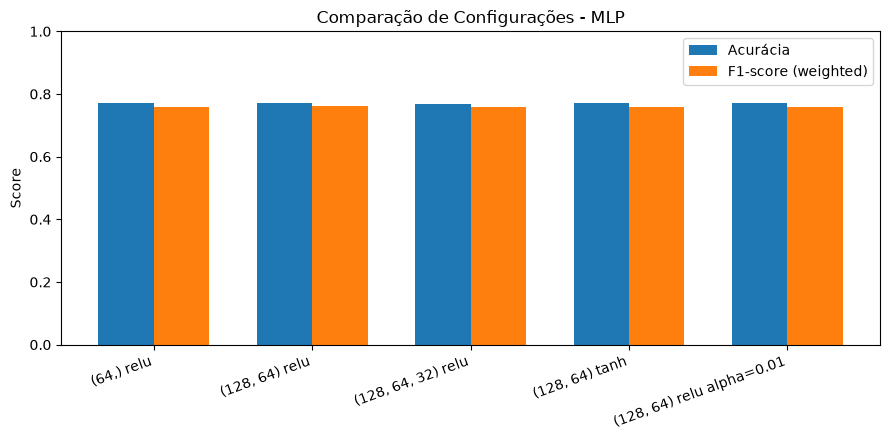

In [4]:
nomes = list(previsoes.keys())
acc_medias = [accuracy_score(previsoes[n][0], previsoes[n][1]) for n in nomes]
f1_medias = [f1_score(previsoes[n][0], previsoes[n][1], average="macro") for n in nomes]

x = np.arange(len(nomes))
largura = 0.35

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - largura/2, acc_medias, largura, label="Acurácia")
ax.bar(x + largura/2, f1_medias, largura, label="F1-score (macro)")
ax.set_xticks(x)
ax.set_xticklabels(nomes, rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Comparação de Configurações - MLP")
ax.legend()
plt.tight_layout()
Path("../../media").mkdir(parents=True, exist_ok=True)
plt.savefig("../../media/comparacao_mlp.png", dpi=300, bbox_inches="tight")
plt.show()

### 5. Matriz de confusão do melhor modelo

Melhor configuração: (128, 64) relu


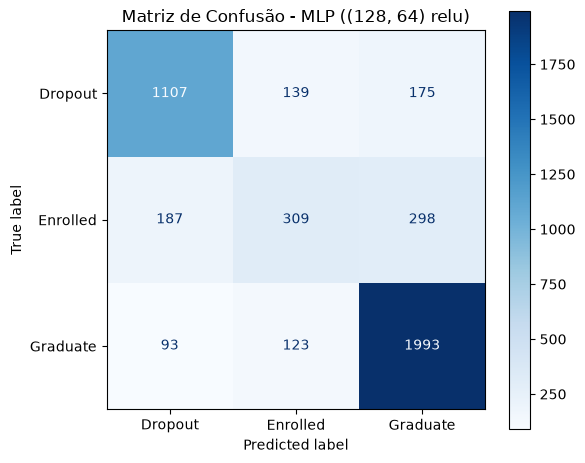

In [5]:
melhor = max(previsoes, key=lambda n: f1_score(previsoes[n][0], previsoes[n][1], average="macro"))
print(f"Melhor configuração: {melhor}")
yt, yp = previsoes[melhor]
print(classification_report(yt, yp))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(yt, yp, ax=ax, cmap="Blues")
ax.set_title(f"Matriz de Confusão - MLP ({melhor})")
plt.tight_layout()
Path("../../media").mkdir(parents=True, exist_ok=True)
plt.savefig("../../media/matriz_confusao_mlp.png", dpi=300, bbox_inches="tight")
plt.show()